In [1]:
from functools import cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile

# Figure style, the same as in phase_sorting.ipynb.
plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

# Folder with the saved measurements. It holds one profiles.parquet for each sample.
MEASUREMENTS = Path("ihc_results/measurements")
# Table of distance ranges to leave out, with the columns of IHC_exclusions.csv.
EXCLUSIONS = ""
# Sides to leave out. Each is written as "N_1/triple_ihc_003_P1/side0".
EXCLUDE = ["N_2/triple_ihc_020_P1/side0", "N_2/triple_ihc_020_P1/side1", "N_2/triple_ihc_019_P1/side0", "N_2/triple_ihc_019_P1/side1"]
# Z method of the saved measurements that is read.
Z_METHOD = "pooled"
# Channel and compartment of the profiles that are compared.
CHANNEL = ("Her7-Venus", "nuclear")
# Width in µm of the rolling mean that smooths each profile.
SMOOTH_UM = 15.0
# Percentile of the smoothed profile that is taken as its baseline.
BASELINE_PERCENTILE = 5.0

# Embryos of the bright group. A side is in this group when its name starts with one
# of these. Every other side is in the second group.
BRIGHT = [f"N_1/triple_ihc_{number:03d}" for number in range(2, 11)]
# Names of the two groups in the figures, and the colour of each group.
BRIGHT_LABEL, OTHER_LABEL = "N_1, samples 002 to 010", "Other samples"
COLORS = {BRIGHT_LABEL: "#D55E00", OTHER_LABEL: "#0072B2"}

# Folders with the nuclear masks and the traced ROIs. The masks are drawn under the ROIs.
MASKS = Path("ihc_results/masks_cellpose_denoised")
ROIS = Path("ihc_results/rois")
# Number of longest sides and number of shortest sides whose ROIs are drawn.
EXTREMES = 100
# An embryo is named in the figure of side lengths when its longer side is more than
# this many times the length of its shorter side.
PAIR_RATIO = 1.2
# Spacing in µm between the columns of the kymograph that is sorted by length.
STEP_UM = 2.0

In [2]:
def read_sample(path):
    """Returns the CHANNEL profiles of one sample, with one row for each side and position."""
    saved = pd.read_parquet(path, filters=[("method", "==", Z_METHOD)])
    saved = saved[(saved.channel == CHANNEL[0]) & (saved.compartment == CHANNEL[1])]
    # Add the sums of all Z-planes at each position, then divide once.
    keys = ["replicate", "sample_id", "side", "position_index"]
    pooled = saved.groupby(keys, as_index=False, observed=True).agg(
        distance_um=("distance_um", "first"), total=("masked_sum", "sum"), weight=("mask_weight", "sum"))
    # A position without any mask coverage has no value.
    pooled["value"] = pooled.total / pooled.weight.where(pooled.weight > 0)
    pooled["name"] = pooled.replicate + "/" + pooled.sample_id + "/" + pooled.side
    return pooled


table = pd.concat([read_sample(path) for path in sorted(MEASUREMENTS.glob("*/*/profiles.parquet"))])
table = table[~table.name.isin(EXCLUDE)]

# Values inside an excluded range are removed. The next cell fills these gaps from their neighbours.
# for row in pd.read_csv(EXCLUSIONS).itertuples():
#     inside = ((table.name == f"{row.replicate}/{row.sample_id}/{row.side}")
#               & table.distance_um.between(row.start_um, row.stop_um))
#     table.loc[inside, "value"] = np.nan

In [ ]:
def smooth(distance, values):
    """Returns a profile with its gaps filled from their neighbours and a rolling mean of width SMOOTH_UM."""
    filled = pd.Series(values).interpolate(limit_direction="both")
    window = max(1, round(SMOOTH_UM / (distance[1] - distance[0])))
    return filled.rolling(window, center=True, min_periods=1).mean().to_numpy()


def roi_lengths(embryo):
    """Returns the length in µm of each side in the rois.csv of one embryo.

    The length is measured along the straight segments between the clicked points, as Fiji
    shows it while the line is drawn. The pixel size is read from a mask of the embryo.
    """
    path = ROIS / embryo / "rois.csv"
    if not path.exists():
        return {}
    masks = sorted(ROIS.parent.glob(f"masks_*/{embryo}/Mask.tif"))
    if not masks:
        raise FileNotFoundError(f"No mask of {embryo} was found to read its pixel size from.")
    with tifffile.TiffFile(masks[0]) as tif:
        pixels, unit = tif.pages[0].tags["XResolution"].value
    um_per_pixel = unit / pixels
    lengths = {}
    for side, line in pd.read_csv(path).sort_values("vertex_index").groupby("roi_id"):
        steps = np.diff(line[["x_px", "y_px"]].to_numpy(), axis=0)
        lengths[side] = np.hypot(steps[:, 0], steps[:, 1]).sum() * um_per_pixel
    return lengths


# For each side, the smoothed profile with its distance in µm from the posterior end,
# and the baseline and peak of the side.
profiles, rows = {}, []
for name, side in table.sort_values("position_index").groupby("name"):
    distance = side.distance_um.to_numpy()
    smoothed = smooth(distance, side.value.to_numpy())
    profiles[name] = (distance, smoothed)
    baseline = np.percentile(smoothed, BASELINE_PERCENTILE)
    # The peak is the highest point of the profile after the baseline is subtracted.
    rows.append({"name": name, "baseline": baseline, "peak": smoothed.max() - baseline})

sides = pd.DataFrame(rows)
sides["embryo"] = sides.name.str.rsplit("/", n=1).str[0]
sides["side"] = sides.name.str.rsplit("/", n=1).str[1]
sides["group"] = np.where(sides.name.str.startswith(tuple(BRIGHT)), BRIGHT_LABEL, OTHER_LABEL)
# The length of each side comes from the current rois.csv. A side that is no longer in
# the CSV has no length.
lengths = {embryo: roi_lengths(embryo) for embryo in sides.embryo.unique()}
sides["length"] = [lengths[embryo].get(side, np.nan) for embryo, side in zip(sides.embryo, sides.side)]
sides.groupby("group")[["baseline", "peak"]].describe().round(0).T

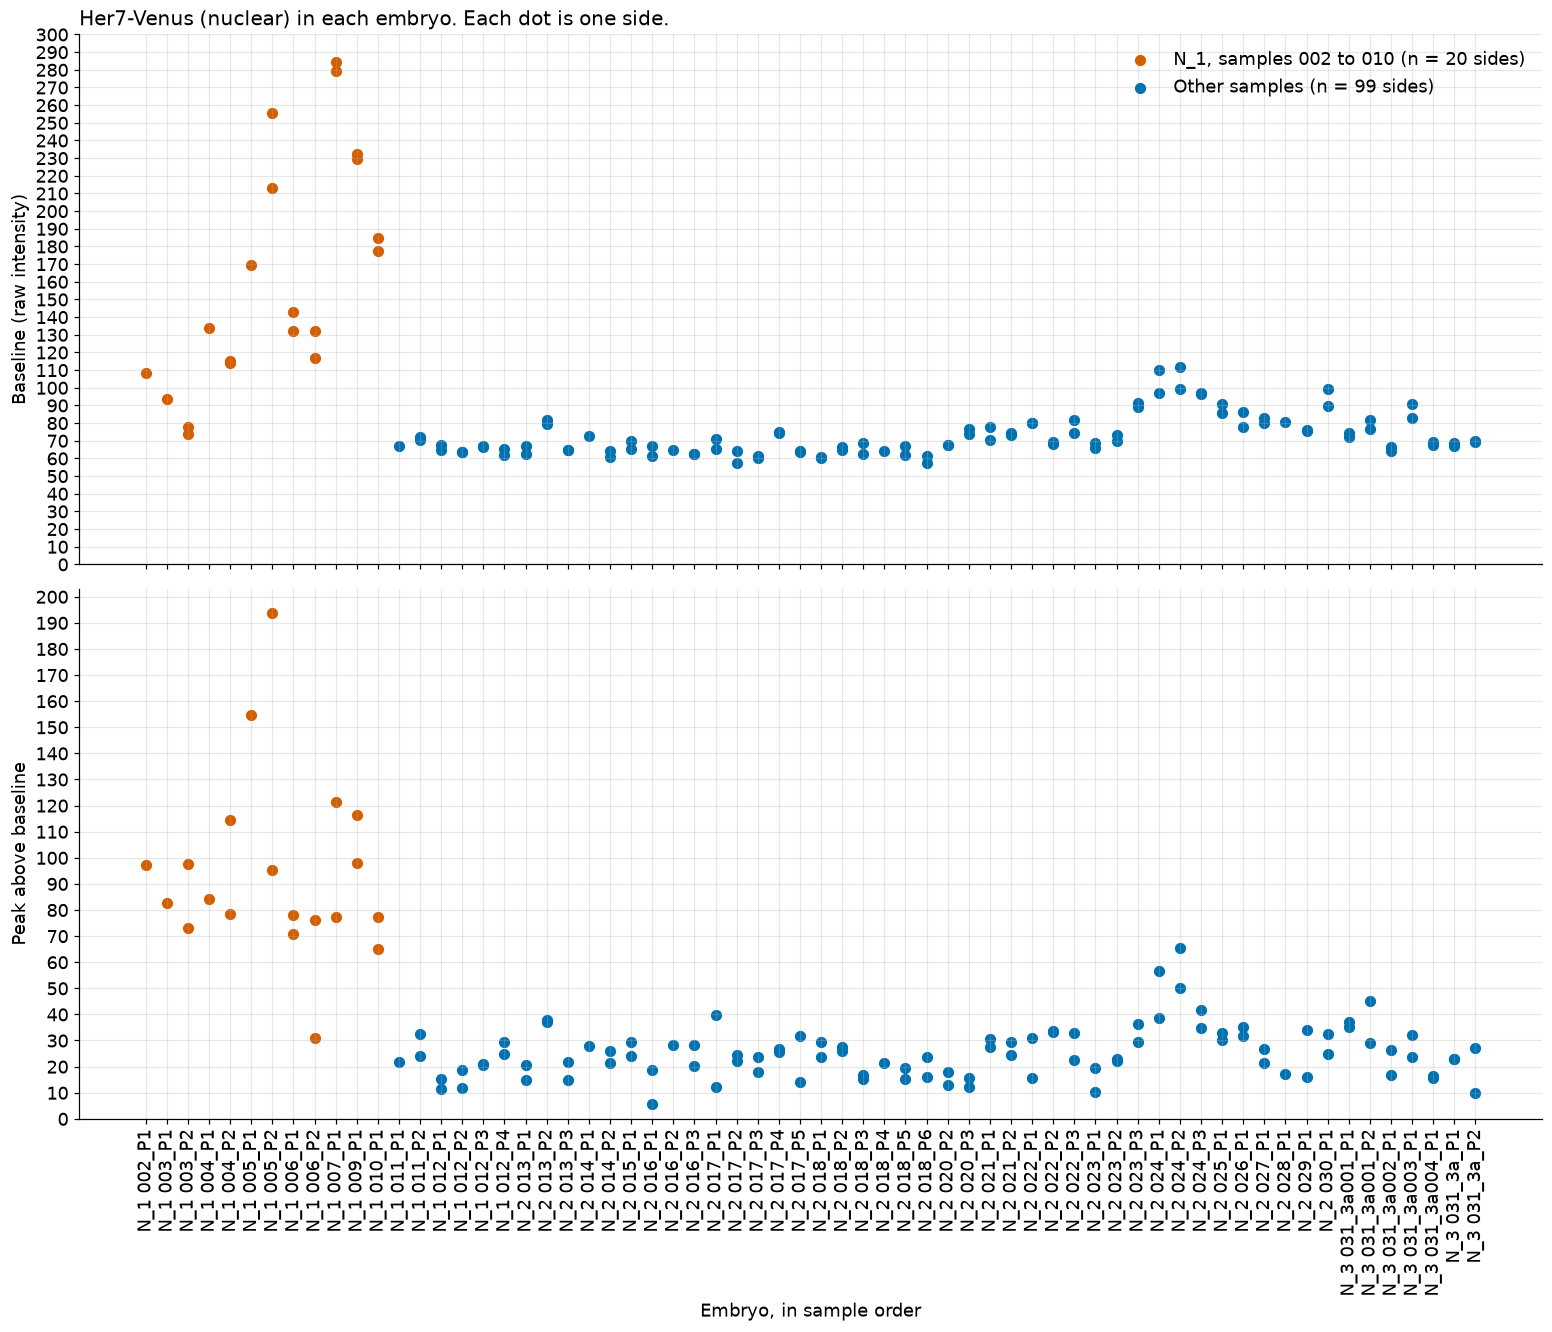

In [4]:
# The embryos are placed along the x axis in sample order. The names sort in this order.
embryos = sorted(sides.embryo.unique())
sides["x"] = sides.embryo.map({embryo: i for i, embryo in enumerate(embryos)})

fig, axes = plt.subplots(2, 1, figsize=(14, 12), sharex=True, constrained_layout=True)
for ax, column, label in zip(axes, ["baseline", "peak"], ["Baseline (raw intensity)", "Peak above baseline"]):
    for group, color in COLORS.items():
        chosen = sides[sides.group == group]
        ax.scatter(chosen.x, chosen[column], color=color, s=40, label=f"{group} (n = {len(chosen)} sides)")
    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
axes[0].set_title(f"{CHANNEL[0]} ({CHANNEL[1]}) in each embryo. Each dot is one side.")
axes[0].set_yticks(range(0, 301, 10), [f"{i}" for i in range(0, 301, 10)])
axes[0].legend(frameon=False)
# Each tick is labelled with the replicate, the sample number and the position.
axes[1].set_xticks(range(len(embryos)), [embryo.replace("/triple_ihc_", " ") for embryo in embryos], rotation=90)
axes[1].set_yticks(range(0, 201, 10), [f"{i}" for i in range(0, 201, 10)])
axes[1].set_xlabel("Embryo, in sample order")
plt.show()

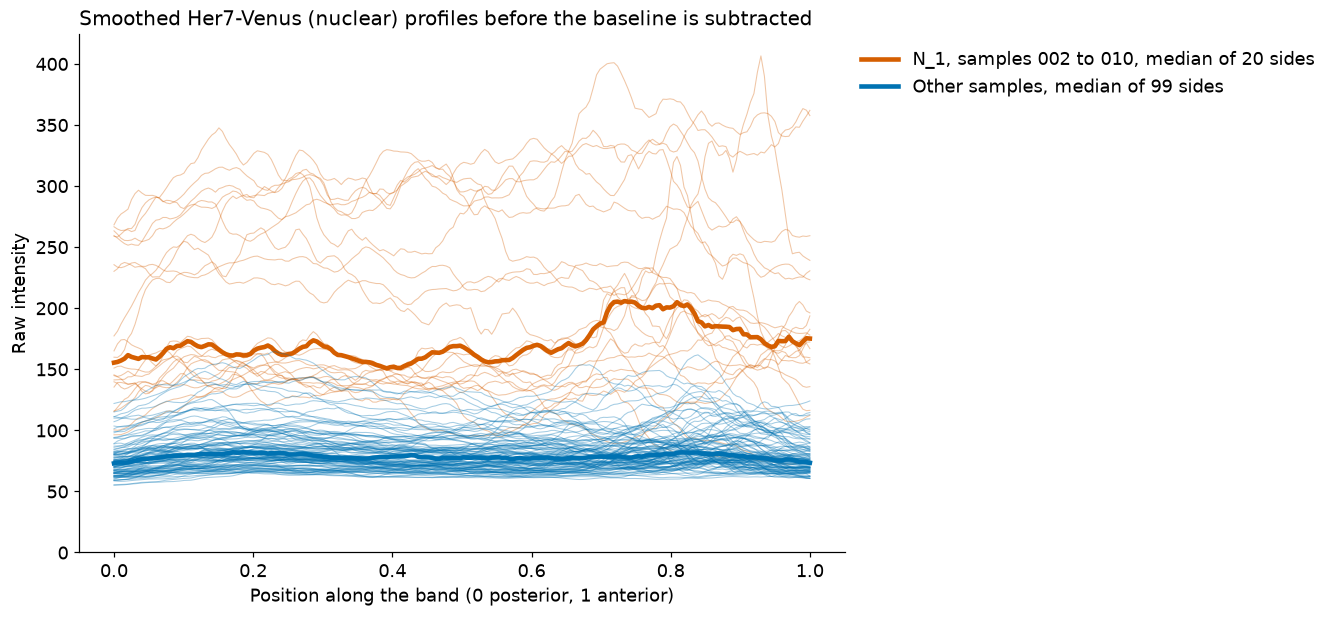

In [5]:
# Every profile is read at the same 200 points of the relative axis, which lets the
# profiles of a group be stacked and their median be taken at each point. The relative
# axis runs from 0 at the posterior end of the band to 1 at its anterior end.
grid = np.linspace(0, 1, 200)

fig, ax = plt.subplots(figsize=(12, 5.5), constrained_layout=True)
for group, color in COLORS.items():
    names = sides.name[sides.group == group]
    stacked = np.array([np.interp(grid, profiles[name][0] / profiles[name][0][-1], profiles[name][1]) for name in names])
    # Each side is a thin line. The median of the group is a thick line.
    ax.plot(grid, stacked.T, color=color, lw=0.7, alpha=0.35)
    ax.plot(grid, np.median(stacked, axis=0), color=color, lw=3, label=f"{group}, median of {len(names)} sides")
ax.set(title=f"Smoothed {CHANNEL[0]} ({CHANNEL[1]}) profiles before the baseline is subtracted",
       xlabel="Position along the band (0 posterior, 1 anterior)", ylabel="Raw intensity", ylim=(0, None))
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

In [6]:
# Summary of the side lengths in µm. Below it, the table lists the sides longer than the
# 90th percentile and shorter than the 10th percentile of all sides.
length = sides.length
q10, q25, q75, q90 = length.quantile([0.10, 0.25, 0.75, 0.90])
print(f"Sides:            {len(length)}")
print(f"Median:           {length.median():.0f} µm")
print(f"IQR:              {q75 - q25:.0f} µm ({q25:.0f} to {q75:.0f})")
print(f"Mean ± SD:        {length.mean():.0f} ± {length.std():.0f} µm")
print(f"10th percentile:  {q10:.0f} µm")
print(f"90th percentile:  {q90:.0f} µm")

long = sides[length > q90].sort_values("length", ascending=False).assign(label="long")
short = sides[length < q10].sort_values("length").assign(label="short")
pd.concat([long, short])[["name", "length", "label"]].round(0).reset_index(drop=True)

Sides:            119
Median:           405 µm
IQR:              64 µm (377 to 442)
Mean ± SD:        406 ± 53 µm
10th percentile:  338 µm
90th percentile:  472 µm


,name,length,label
0,N_2/triple_ihc_021_P1/side0,548.0,long
1,N_2/triple_ihc_026_P1/side1,536.0,long
2,N_1/triple_ihc_011_P2/side1,513.0,long
3,N_2/triple_ihc_020_P2/side1,507.0,long
4,N_1/triple_ihc_012_P4/side1,497.0,long
5,N_1/triple_ihc_005_P1/side0,487.0,long
6,N_2/triple_ihc_021_P1/side1,487.0,long
7,N_2/triple_ihc_026_P1/side0,479.0,long
8,N_2/triple_ihc_024_P2/side1,478.0,long
9,N_2/triple_ihc_017_P5/side0,474.0,long


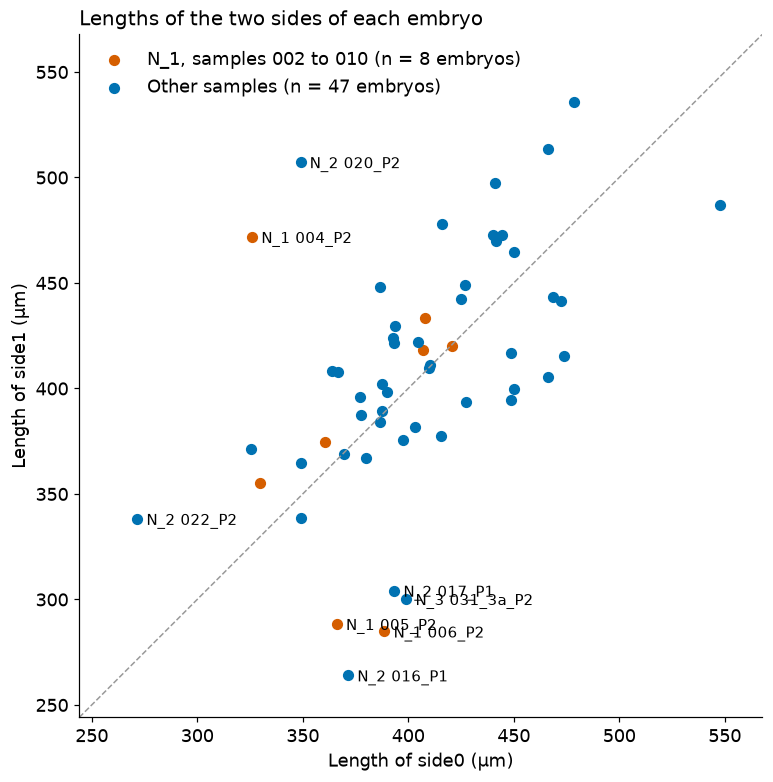

In [7]:
# One point for each embryo with both sides measured. Its x is the length of side0 and
# its y is the length of side1. Both sides come from one embryo at one stage, so their
# lengths are expected to be close.
pairs = sides.pivot(index="embryo", columns="side", values="length").dropna()
pairs["group"] = sides.groupby("embryo").group.first()

fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
for group, color in COLORS.items():
    chosen = pairs[pairs.group == group]
    ax.scatter(chosen.side0, chosen.side1, color=color, s=40, label=f"{group} (n = {len(chosen)} embryos)")
# Points on the dashed line have two sides of the same length.
limits = [pairs[["side0", "side1"]].min().min() - 20, pairs[["side0", "side1"]].max().max() + 20]
ax.plot(limits, limits, color="0.6", ls="--", lw=1)
# Embryos whose longer side is more than PAIR_RATIO times the shorter side are named.
ratio = pairs[["side0", "side1"]].max(axis=1) / pairs[["side0", "side1"]].min(axis=1)
for embryo, pair in pairs[ratio > PAIR_RATIO].iterrows():
    ax.annotate(embryo.replace("/triple_ihc_", " "), (pair.side0, pair.side1),
                xytext=(6, -4), textcoords="offset points", fontsize=10)
ax.set(xlim=limits, ylim=limits, aspect="equal", title="Lengths of the two sides of each embryo",
       xlabel="Length of side0 (µm)", ylabel="Length of side1 (µm)")
ax.legend(frameon=False)
plt.show()

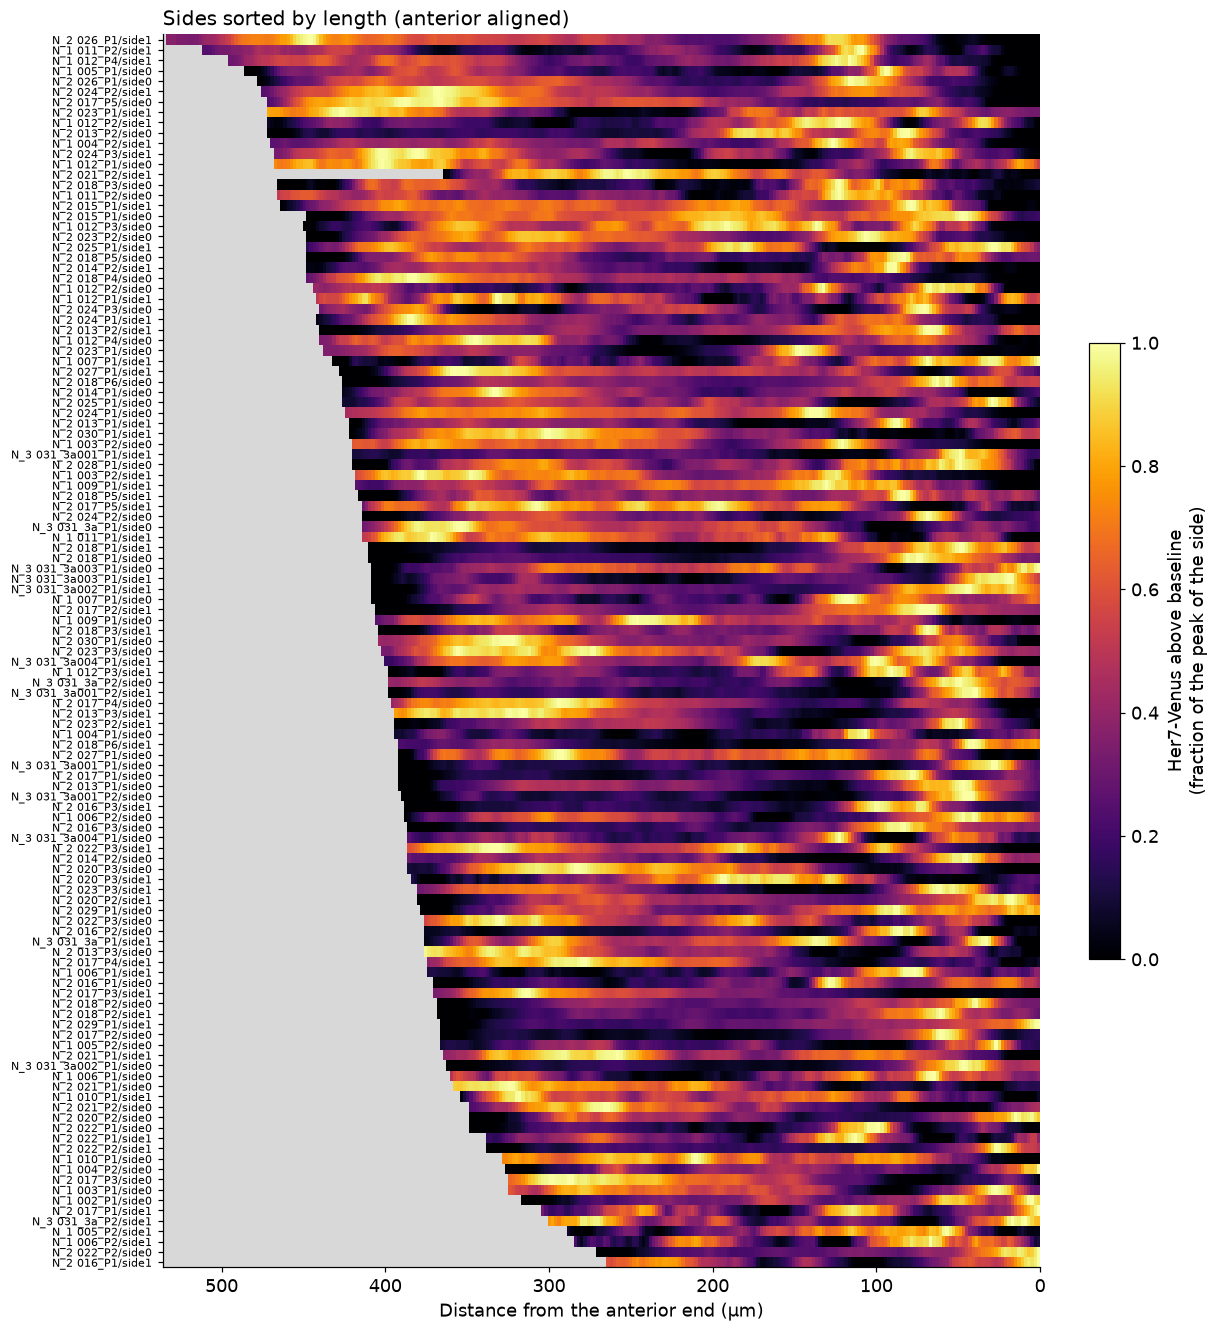

In [11]:
# Each row is one side, with the rows sorted from the longest side at the top to the
# shortest at the bottom. The ends named by ALIGN are lined up: posterior ends on the
# left, or anterior ends on the right. Each row is scaled from 0 at its baseline to 1 at
# its peak. This removes the brightness difference between the groups and leaves the
# stripe pattern. Grey marks positions past the end of a band.
ALIGN = "anterior"  # "posterior" or "anterior"
order = sides.sort_values("length", ascending=False)
grid = np.arange(0, max(profiles[name][0][-1] for name in order.name) + STEP_UM, STEP_UM)
stacked = []
for side in order.itertuples():
    distance, values = profiles[side.name]
    scaled = (values - side.baseline) / side.peak
    if ALIGN == "anterior":
        # Measure from the anterior end instead, so that the anterior ends share 0.
        distance, scaled = distance[-1] - distance[::-1], scaled[::-1]
    stacked.append(np.interp(grid, distance, scaled, right=np.nan))

fig, ax = plt.subplots(figsize=(11, 12), constrained_layout=True)
image = ax.imshow(np.array(stacked), aspect="auto", interpolation="nearest", vmin=0, vmax=1,
                  cmap=plt.get_cmap("inferno").with_extremes(bad="0.85"), extent=(0, grid[-1], len(order), 0))
# For anterior alignment the x axis is reversed, so that posterior stays on the left and
# the anterior ends, at 0, line up on the right.
if ALIGN == "anterior":
    ax.invert_xaxis()
ax.set_yticks(np.arange(len(order)) + 0.5, order.name.str.replace("/triple_ihc_", " "), fontsize=7)
ax.set(title=f"Sides sorted by length ({ALIGN} aligned)",
       xlabel=f"Distance from the {ALIGN} end (µm)")
fig.colorbar(image, ax=ax, shrink=0.5, label=f"{CHANNEL[0]} above baseline\n(fraction of the peak of the side)")
plt.show()

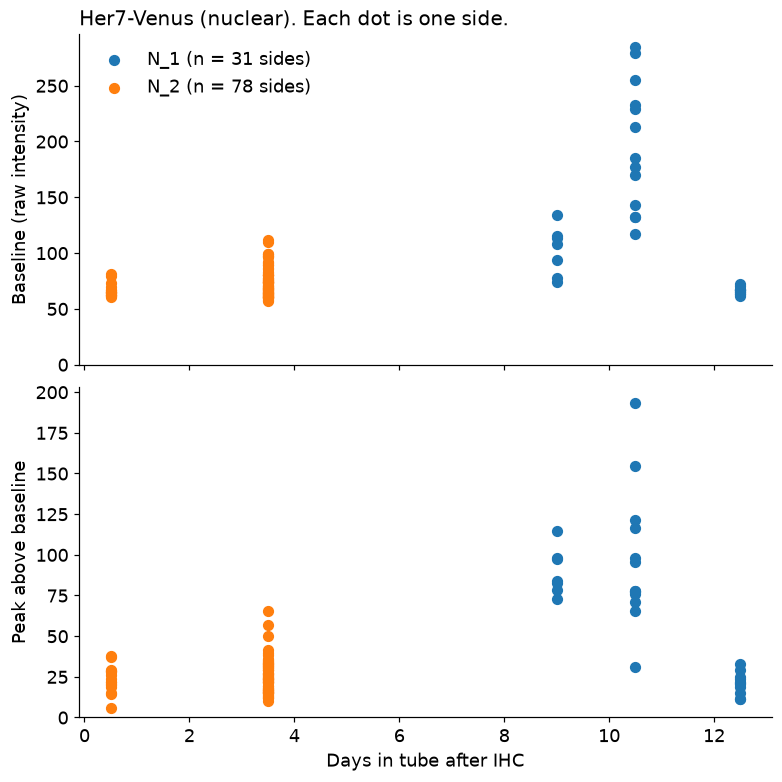

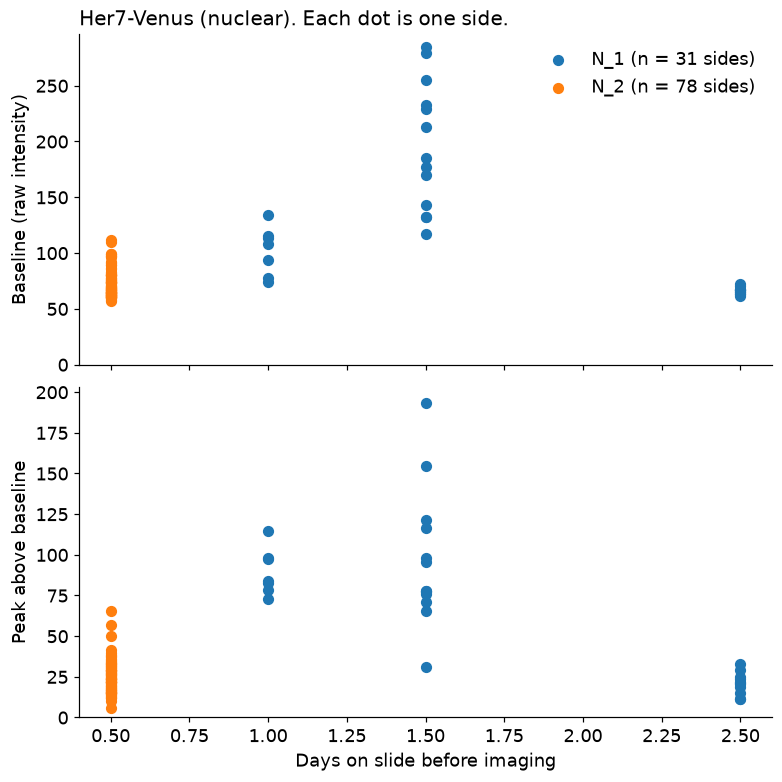

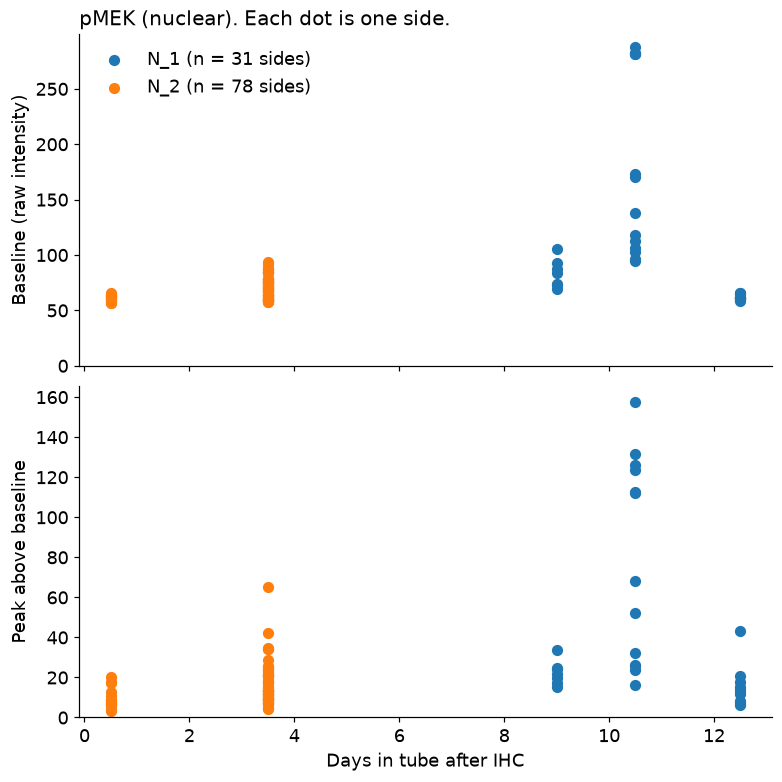

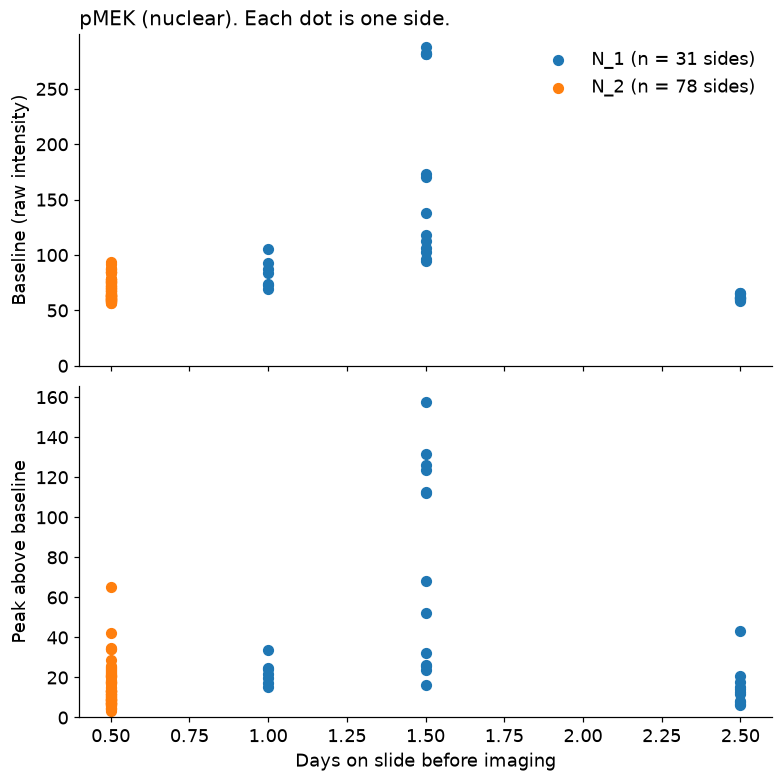

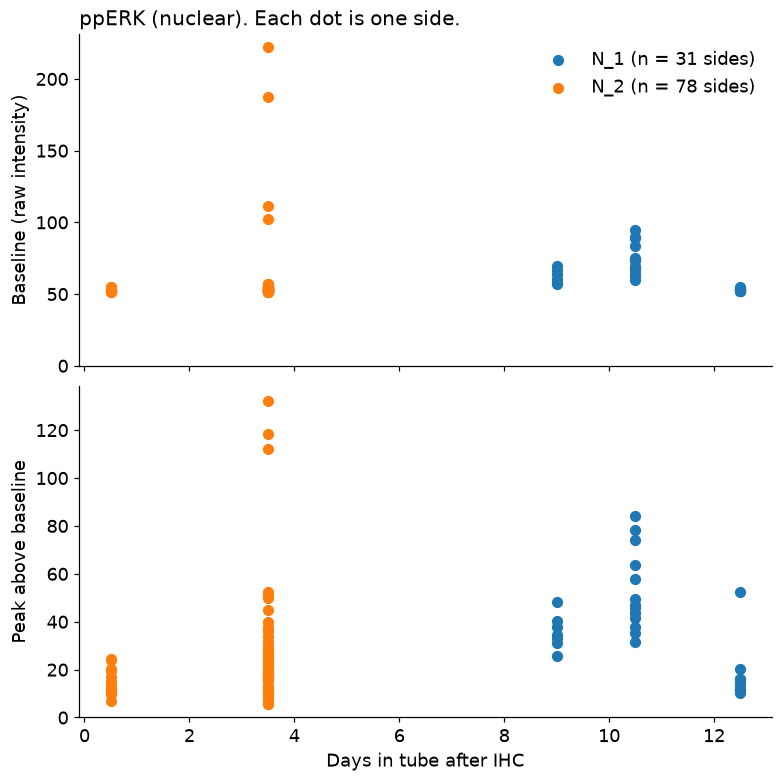

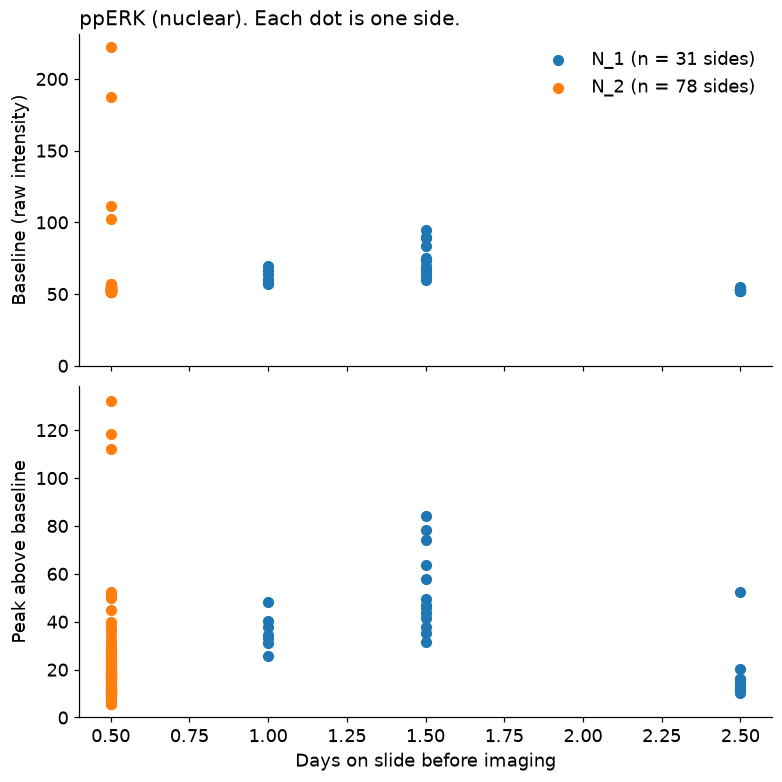

In [9]:
# Days each sample spent in the tube after IHC and on the slide before imaging. Where the
# chat gives a range of days, the middle of the range is used.
def days_in_tube_and_on_slide(sample_number):
    if sample_number <= 4:
        return 9, 1
    if sample_number <= 10:
        return 10.5, 1.5
    if sample_number <= 12:
        return 12.5, 2.5
    if sample_number <= 16:
        return 0.5, 0.5
    return 3.5, 0.5


# The nuclear profiles of all three channels are read from every sample.
frames = []
for path in sorted(MEASUREMENTS.glob("*/*/profiles.parquet")):
    saved = pd.read_parquet(path, filters=[("method", "==", Z_METHOD)])
    frames.append(saved[saved.compartment == "nuclear"])
saved = pd.concat(frames)

# The sums of all Z-planes at each position are added, then divided once.
keys = ["replicate", "sample_id", "side", "channel", "position_index"]
pooled = saved.groupby(keys, as_index=False, observed=True).agg(
    distance_um=("distance_um", "first"), total=("masked_sum", "sum"), weight=("mask_weight", "sum"))
pooled["value"] = pooled.total / pooled.weight.where(pooled.weight > 0)

# # Values inside an excluded range are removed.
# for row in pd.read_csv(EXCLUSIONS).itertuples():
#     inside = ((pooled.replicate == row.replicate) & (pooled.sample_id == row.sample_id)
#               & (pooled.side == row.side) & pooled.distance_um.between(row.start_um, row.stop_um))
#     pooled.loc[inside, "value"] = np.nan

# The baseline and peak of each side are found for each channel, in the same way as in the cells above.
rows = []
pooled = pooled.sort_values("position_index")
for (replicate, sample_id, side, channel), profile in pooled.groupby(["replicate", "sample_id", "side", "channel"]):
    smoothed = smooth(profile.distance_um.to_numpy(), profile.value.to_numpy())
    baseline = np.percentile(smoothed, BASELINE_PERCENTILE)
    # The sample number is the third part of a name such as triple_ihc_005_P2.
    tube, slide = days_in_tube_and_on_slide(int(sample_id.split("_")[2]))
    rows.append({"replicate": replicate, "channel": channel, "baseline": baseline,
                 "peak": smoothed.max() - baseline, "tube": tube, "slide": slide})
intensity = pd.DataFrame(rows)

# Each channel gets two figures. One plots intensity against days in the tube and the
# other against days on the slide. The top panel shows the baseline and the bottom panel the peak.
colors = {"N_1": "tab:blue", "N_2": "tab:orange"}
for channel in ["Her7-Venus", "pMEK", "ppERK"]:
    channel_data = intensity[intensity.channel == channel]
    for days, xlabel in [("tube", "Days in tube after IHC"), ("slide", "Days on slide before imaging")]:
        fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 7), sharex=True, constrained_layout=True)
        for replicate, color in colors.items():
            data = channel_data[channel_data.replicate == replicate]
            top.scatter(data[days], data.baseline, color=color, s=40, label=f"{replicate} (n = {len(data)} sides)")
            bottom.scatter(data[days], data.peak, color=color, s=40, label=replicate)
        top.set(title=f"{channel} (nuclear). Each dot is one side.", ylabel="Baseline (raw intensity)", ylim=(0, None))
        bottom.set(xlabel=xlabel, ylabel="Peak above baseline", ylim=(0, None))
        top.legend(frameon=False)
        plt.show()
